# Dự đoán Kết quả Trận đấu (Thắng/Hòa/Thua) với XGBoost, MLflow và SHAP

In [ ]:
# 1. Cài đặt các thư viện cần thiết
!pip install -q mlflow==3.16.1 xgboost shap duckdb pysocks


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 35.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1

In [ ]:
# Upload file colab_utils.py từ máy tính
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

import importlib
import colab_utils
importlib.invalidate_caches()
importlib.reload(colab_utils)
print("File đang dùng:", colab_utils.__file__)


Saving colab_utils.py to colab_utils.py
Uploaded: ['colab_utils.py']
File đang dùng: /content/colab_utils.py


In [ ]:
import colab_utils
from google.colab import userdata

colab_utils.install_tailscale()

status = colab_utils.setup_tailscale()
print("Connected check:", colab_utils.tailscale_is_connected())


Đang cài Tailscale...
Cài Tailscale thành công.
100.113.209.29   google-colab-1  taohshsh1303@  linux    -                           
100.116.34.36    ai-lab          taohshsh1303@  linux    -                           
100.118.178.119  baongoc         taohshsh1303@  windows  -                           
100.94.113.41    google-colab-3  taohshsh1303@  linux    offline, last seen 1d ago   
100.98.11.71     google-colab-4  taohshsh1303@  linux    offline, last seen 1d ago   
100.82.94.58     google-colab-5  taohshsh1303@  linux    offline, last seen 1d ago   
100.70.251.118   google-colab-6  taohshsh1303@  linux    offline, last seen 16h ago  
100.83.52.70     google-colab    taohshsh1303@  linux    offline, last seen 15h ago  
100.70.174.90    vmlab1          taohshsh1303@  linux    -
HTTP proxy: http://localhost:1056
SOCKS5 proxy: socks5://localhost:1055
Connected check: True


In [ ]:
MLFLOW_URI = "http://100.116.34.36:8080"
# EXPERIMENT_NAME = "Match-Prediction-XGBoost"

# colab_utils.setup_mlflow(
#     server_uri=MLFLOW_URI,
#     experiment=EXPERIMENT_NAME,
# )

In [ ]:
import duckdb
import pandas as pd
from google.colab import userdata

def load_data_from_minio():
    print("Kết nối MinIO...")

    con = duckdb.connect(":memory:")
    con.execute("INSTALL httpfs")
    con.execute("LOAD httpfs")

    minio_endpoint = "20.41.113.183:9000"
    minio_ak = userdata.get("MINIO_ACCESS_KEY")
    minio_sk = userdata.get("MINIO_SECRET_KEY")

    if not minio_ak or not minio_sk:
        raise ValueError("Thiếu MinIO credentials trong Colab Secrets")

    con.execute(f"""
        CREATE OR REPLACE SECRET minio_secret (
            TYPE S3,
            KEY_ID '{minio_ak.replace("'", "''")}',
            SECRET '{minio_sk.replace("'", "''")}',
            ENDPOINT '{minio_endpoint}',
            URL_STYLE 'path',
            USE_SSL false
        )
    """)

    path = "s3://football-lake/dwh/mart_ml_match_features.parquet"

    print(f"Đang tải: {path}")
    df = con.execute(
        f"SELECT * FROM read_parquet('{path}')"
    ).df()

    con.close()
    return df

df = load_data_from_minio()

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Kết nối MinIO...


TimeoutException: Requesting secret MINIO_ACCESS_KEY timed out. Secrets can only be fetched when running from the Colab UI.

In [ ]:


print("Shape:", df.shape)
df.to_csv("mart_ml_team_match_features_audit.csv", index=False)

print("Đã xuất CSV:", "mart_ml_team_match_features_audit.csv")

Shape: (31674, 214)
Đã xuất CSV: mart_ml_team_match_features_audit.csv


## kiểm tra data

In [ ]:

# 1. Kích thước và cấu trúc tổng quan
print("Kích thước:", df.shape)
print("\nTên các cột:")
print(df.columns.tolist())

print("\nKiểu dữ liệu:")
display(df.dtypes.to_frame("dtype"))

# 2. Xem một số dòng đầu và cuối
display(df.head(10))
display(df.tail(5))

# 3. Thống kê các cột số
display(df.describe().T)

# 4. Kiểm tra giá trị thiếu và tỷ lệ thiếu
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)

display(missing[missing["missing_count"] > 0])

# 5. Kiểm tra trùng lặp
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())

if "match_id" in df.columns:
    print("Số match_id trùng:", df["match_id"].duplicated().sum())

# 6. Kiểm tra các cột quan trọng
for col in ["split", "is_warm", "is_labeled", "y_result_code"]:
    if col in df.columns:
        print(f"\nPhân bố {col}:")
        display(df[col].value_counts(dropna=False).to_frame("count"))

# 7. Kiểm tra phân bố nhãn theo từng tập
if {"split", "y_result_code"}.issubset(df.columns):
    display(pd.crosstab(
        df["split"],
        df["y_result_code"],
        margins=True,
        dropna=False
    ))

# 8. Kiểm tra các cột feature
features_all = [c for c in df.columns if c.startswith("f_")]
features_numeric = [
    c for c in features_all
    if pd.api.types.is_numeric_dtype(df[c])
]

print("\nTổng cột f_:", len(features_all))
print("Cột f_ dạng số:", len(features_numeric))
print("Cột f_ không phải dạng số:",
      sorted(set(features_all) - set(features_numeric)))

display(df[features_numeric].head())


Kích thước: (31028, 214)

Tên các cột:
['match_key', 'competition_key', 'season', 'match_date', 'kickoff_utc', 'home_key', 'away_key', 'fdo_match_id', 'understat_match_id', 'af_fixture_id', 'openliga_match_id', 'status', 'is_finished', 'is_labeled', 'split', 'is_warm', 'odds_src', 'has_odds', 'has_xg', 'goals_conflict', 'in_fdo', 'in_couk', 'in_understat', 'in_api_football', 'in_openliga', 'in_odds_api', 'f_home_n_prev', 'f_away_n_prev', 'f_diff_n_prev', 'f_home_pts_l3', 'f_away_pts_l3', 'f_diff_pts_l3', 'f_home_gf_l3', 'f_away_gf_l3', 'f_diff_gf_l3', 'f_home_ga_l3', 'f_away_ga_l3', 'f_diff_ga_l3', 'f_home_pts_l5', 'f_away_pts_l5', 'f_diff_pts_l5', 'f_home_gf_l5', 'f_away_gf_l5', 'f_diff_gf_l5', 'f_home_ga_l5', 'f_away_ga_l5', 'f_diff_ga_l5', 'f_home_gd_l5', 'f_away_gd_l5', 'f_diff_gd_l5', 'f_home_win_rate_l5', 'f_away_win_rate_l5', 'f_diff_win_rate_l5', 'f_home_cs_rate_l5', 'f_away_cs_rate_l5', 'f_diff_cs_rate_l5', 'f_home_btts_rate_l5', 'f_away_btts_rate_l5', 'f_diff_btts_rate_l5', '

,dtype
match_key,object
competition_key,object
season,int64
match_date,datetime64[us]
kickoff_utc,datetime64[us]
...,...
y_away_shots,Int32
y_home_shots_target,Int32
y_away_shots_target,Int32
y_total_corners,Int32


,match_key,competition_key,season,match_date,kickoff_utc,home_key,away_key,fdo_match_id,understat_match_id,af_fixture_id,...,y_us_xg_p_draw,y_us_xg_p_away,y_home_xg,y_away_xg,y_home_shots,y_away_shots,y_home_shots_target,y_away_shots_target,y_total_corners,y_total_cards
0,0c754c91c82b09bcbb4a2c7e24f65d25,CHAMPIONSHIP,2023,2023-09-23,2023-09-23 14:00:00,Plymouth,Norwich City,None,None,None,...,NaN,NaN,NaN,NaN,16,11,10,6,9,1
1,730a36a4f3b8d6884af048665295406f,CHAMPIONSHIP,2023,2023-10-24,2023-10-24 18:45:00,Swansea,Watford,None,None,None,...,NaN,NaN,NaN,NaN,9,12,3,5,10,3
2,e4680461ec08ce03e534d0e988fac9c7,CHAMPIONSHIP,2023,2023-10-28,2023-10-28 14:00:00,Middlesbrough,Stoke,None,None,None,...,NaN,NaN,NaN,NaN,9,13,3,6,12,4
3,44465f39f91fb89a3a9be84dba4587af,CHAMPIONSHIP,2023,2023-11-04,2023-11-04 15:00:00,West Brom,Hull City,None,None,None,...,NaN,NaN,NaN,NaN,10,9,5,4,3,2
4,cee639c1056ae158b36a3eb6b74cd912,CHAMPIONSHIP,2023,2023-11-25,2023-11-25 15:00:00,Stoke,Blackburn,None,None,None,...,NaN,NaN,NaN,NaN,12,7,1,4,8,3
5,1c73cfb2f02d26534a09d0deb56b1661,CHAMPIONSHIP,2023,2023-11-28,2023-11-28 19:45:00,Middlesbrough,Preston,None,None,None,...,NaN,NaN,NaN,NaN,13,6,8,1,10,2
6,907fdca87f05e6f28ea45965be86574a,CHAMPIONSHIP,2023,2023-12-02,2023-12-02 15:00:00,Ipswich Town,Coventry City,None,None,None,...,NaN,NaN,NaN,NaN,13,15,3,1,7,3
7,625da45a1257246c26b5bdd7d4c9b19f,CHAMPIONSHIP,2023,2023-12-09,2023-12-09 15:00:00,Cardiff,Millwall,None,None,None,...,NaN,NaN,NaN,NaN,7,10,3,3,6,3
8,b7d4f84c6b6eb395e2fe164a0fe7b1a2,CHAMPIONSHIP,2023,2023-12-17,2023-12-17 12:00:00,West Brom,Stoke,None,None,None,...,NaN,NaN,NaN,NaN,16,9,7,1,22,4
9,ff6011233cf3f8af3b9b8445c37df2c3,CHAMPIONSHIP,2023,2023-12-26,2023-12-26 15:00:00,Rotherham,Middlesbrough,None,None,None,...,NaN,NaN,NaN,NaN,3,19,1,5,11,0


,match_key,competition_key,season,match_date,kickoff_utc,home_key,away_key,fdo_match_id,understat_match_id,af_fixture_id,...,y_us_xg_p_draw,y_us_xg_p_away,y_home_xg,y_away_xg,y_home_shots,y_away_shots,y_home_shots_target,y_away_shots_target,y_total_corners,y_total_cards
31023,d7a9e1c2c20e6ad06566428cff7d7473,UCL,2026,2026-09-09,2026-09-09 16:45:00,Barcelona,Feyenoord Rotterdam,575329,None,None,...,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
31024,9f6b6c1ee6772c7403c4becaa601f425,BUNDESLIGA,2026,2026-09-12,2026-09-12 13:30:00,Hoffenheim,VfB Stuttgart,565794,None,None,...,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
31025,c39656f3bb3cefe3e042c9912495d5a1,BUNDESLIGA,2026,2026-10-10,2026-10-10 13:30:00,Augsburg,Bayern Munich,565819,None,None,...,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
31026,4836f9047c76c42417af5249979712cf,CHAMPIONSHIP,2020,2020-09-12,2020-09-12 14:00:00,QPR,Nottingham Forest,None,None,None,...,NaN,NaN,NaN,NaN,9,6,3,0,6,3
31027,efc1aa92850045bbd2670bb3e811796f,LALIGA,2024,2024-08-25,2024-08-25 15:00:00,Real Madrid,Valladolid,None,None,1208506,...,NaN,NaN,NaN,NaN,17,8,9,2,10,2


,count,mean,min,25%,50%,75%,max,std
season,31028.0,2023.335761,2020.0,2022.0,2023.0,2025.0,2026.0,1.846112
match_date,31028,2024-04-29 22:05:22.083279,2020-08-21 00:00:00,2022-10-19 00:00:00,2024-05-25 00:00:00,2025-11-22 00:00:00,2027-05-30 00:00:00,NaN
kickoff_utc,30036,2024-04-16 03:06:59.581269,2020-08-21 17:00:00,2022-10-09 12:45:00,2024-04-26 18:30:00,2025-11-09 19:45:00,2027-05-30 15:00:00,NaN
f_home_n_prev,31028.0,93.398189,0.0,20.0,71.0,155.0,351.0,82.613526
f_away_n_prev,31028.0,93.870923,0.0,20.0,72.0,156.0,351.0,82.770472
...,...,...,...,...,...,...,...,...
y_away_shots,14045.0,11.112567,0.0,8.0,11.0,14.0,37.0,4.715285
y_home_shots_target,14045.0,4.680171,0.0,3.0,4.0,6.0,20.0,2.524634
y_away_shots_target,14045.0,3.88188,0.0,2.0,4.0,5.0,20.0,2.287743
y_total_corners,14045.0,9.742827,0.0,7.0,10.0,12.0,28.0,3.371635


...


Phân bố y_result_code:


,count
y_result_code,
2,10698
0,7938
1,6198
<NA>,6194


y_result_code,0,1,2,NaN,All
split,,,,,
predict,0,0,0,6194,6194
test,1623,1249,2212,0,5084
train,4595,3700,6188,0,14483
valid,1720,1249,2298,0,5267
All,7938,6198,10698,0,31028



Tổng cột f_: 165
Cột f_ dạng số: 163
Cột f_ không phải dạng số: ['f_away_form5', 'f_home_form5']


,f_home_n_prev,f_away_n_prev,f_diff_n_prev,f_home_pts_l3,f_away_pts_l3,f_diff_pts_l3,f_home_gf_l3,f_away_gf_l3,f_diff_gf_l3,f_home_ga_l3,...,f_matchday,f_comp_tier,f_home_stadium_capacity,f_weather_temp_c,f_weather_precip_mm,f_weather_wind_kmh,f_weather_humidity_pct,f_ref_n_prev,f_ref_avg_cards,f_ref_avg_fouls
0,7,137,-130,1.000000,1.000000,0.000000,1.666667,0.666667,1.000000,2.000000,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,1,NaN,NaN
1,150,142,8,2.000000,1.333333,0.666667,2.000000,0.666667,1.333333,1.666667,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,2,NaN,NaN
2,151,151,0,3.000000,2.000000,1.000000,2.333333,1.000000,1.333333,0.333333,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,3,NaN,NaN
3,144,106,38,2.333333,2.000000,0.333333,1.333333,1.333333,0.000000,0.000000,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,4,NaN,NaN
4,154,154,0,1.666667,1.000000,0.666667,0.666667,1.333333,-0.666667,0.000000,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,5,NaN,NaN


In [ ]:

import pandas as pd
import numpy as np

features_all = [c for c in df.columns if c.startswith("f_")]

# Thống kê missing của feature
feature_missing = pd.DataFrame({
    "missing_count": df[features_all].isna().sum(),
    "missing_pct": df[features_all].isna().mean() * 100,
    "n_unique": df[features_all].nunique(dropna=True),
    "dtype": df[features_all].dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)

print("20 feature thiếu nhiều nhất:")
display(feature_missing.head(20).round(2))

print("Feature thiếu trên 50%:")
display(feature_missing[feature_missing["missing_pct"] > 50].round(2))

# Tỷ lệ nhãn trong từng tập
labeled = df[df["y_result_code"].notna()].copy()

print("Phân bố nhãn theo tập:")
display(pd.crosstab(
    labeled["split"],
    labeled["y_result_code"],
    normalize="index"
).round(3))

# Kiểm tra kiểu dữ liệu hai feature form
for col in ["f_home_form5", "f_away_form5"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(15))


20 feature thiếu nhiều nhất:


,missing_count,missing_pct,n_unique,dtype
f_diff_xgf_l10,29699,95.72,1329,float64
f_diff_xga_l10,29699,95.72,1329,float64
f_diff_xgf_l5,29092,93.76,1936,float64
f_diff_xga_l5,29092,93.76,1936,float64
f_away_xga_l10,29071,93.69,1889,float64
f_away_xgf_l10,29071,93.69,1888,float64
f_home_xga_l10,29066,93.68,1888,float64
f_home_xgf_l10,29066,93.68,1888,float64
f_weather_temp_c,28632,92.28,265,float64
f_weather_humidity_pct,28632,92.28,80,float64


Feature thiếu trên 50%:


,missing_count,missing_pct,n_unique,dtype
f_diff_xgf_l10,29699,95.72,1329,float64
f_diff_xga_l10,29699,95.72,1329,float64
f_diff_xgf_l5,29092,93.76,1936,float64
f_diff_xga_l5,29092,93.76,1936,float64
f_away_xga_l10,29071,93.69,1889,float64
f_away_xgf_l10,29071,93.69,1888,float64
f_home_xga_l10,29066,93.68,1888,float64
f_home_xgf_l10,29066,93.68,1888,float64
f_weather_temp_c,28632,92.28,265,float64
f_weather_humidity_pct,28632,92.28,80,float64


Phân bố nhãn theo tập:


y_result_code,0,1,2
split,,,
test,0.319,0.246,0.435
train,0.317,0.255,0.427
valid,0.327,0.237,0.436



f_home_form5:
f_home_form5
None     3078
WWWWW     643
LLLLL     469
WWWWL     286
LLLWL     284
WWWWD     271
LWWWW     268
LWLLL     268
LLWLL     254
LLLWW     249
WWWLW     249
WLLLL     247
LDLLL     242
LLWWL     242
WWLWW     241
Name: count, dtype: int64

f_away_form5:
f_away_form5
None     3008
WWWWW     667
LLLLL     436
WLWWW     328
WWWLW     318
LWWWW     295
WWWWD     279
LLWLW     274
LLLWW     273
LLLLW     270
LLWLL     253
WWWDW     252
DWWWW     250
WDWWW     250
LLDLL     249
Name: count, dtype: int64


## tiền xử lý

In [ ]:

import numpy as np
import pandas as pd

# ============================================================
# 1. CONFIG
# ============================================================
DATE_COL = "match_date"
TARGET_COL = "y_result_code"
KEY_COL = "match_key"

LABELS = [0, 1, 2]
CLASS_NAMES = ["Away win", "Draw", "Home win"]

# Calendar cutoff: không chia các trận cùng ngày sang nhiều tập.
TRAIN_END = pd.Timestamp("2024-06-30")
VALID_END = pd.Timestamp("2025-06-30")

MAX_MISSING_RATE = 0.15

# ============================================================
# 2. CHECK INPUT
# ============================================================
required_cols = [
    DATE_COL, TARGET_COL, "is_warm", "is_labeled"
]
missing_required = [c for c in required_cols if c not in df.columns]

if missing_required:
    raise KeyError(f"Thiếu cột bắt buộc: {missing_required}")

data = df.copy()

# Chuẩn hóa ngày. match_date là ngày lịch dùng để chia tập.
data[DATE_COL] = pd.to_datetime(data[DATE_COL], errors="coerce")

n_raw = len(data)
data = data.loc[
    data[DATE_COL].notna()
    & data["is_warm"].eq(True)
    & data["is_labeled"].eq(True)
    & data[TARGET_COL].notna()
].copy()

# Ép nhãn về số nguyên, nhưng không âm thầm làm tròn nhãn sai.
target_numeric = pd.to_numeric(data[TARGET_COL], errors="coerce")
bad_target = target_numeric.isna() | ~target_numeric.isin(LABELS)

if bad_target.any():
    examples = data.loc[bad_target, [TARGET_COL]].head(10)
    raise ValueError(
        "Target có giá trị không hợp lệ. Ví dụ:\n"
        + examples.to_string(index=False)
    )

data[TARGET_COL] = target_numeric.astype("int8")

# ============================================================
# 3. REBUILD SPLIT BY CALENDAR DATE
# ============================================================
data["split"] = np.select(
    [
        data[DATE_COL].dt.normalize() <= TRAIN_END,
        data[DATE_COL].dt.normalize() <= VALID_END,
    ],
    ["train", "valid"],
    default="test",
)

# Bắt buộc đủ ba tập.
split_counts = data["split"].value_counts().reindex(
    ["train", "valid", "test"], fill_value=0
)
print("Rows raw:", n_raw)
print("Rows after basic filters:", len(data))
print("\nRows by split:")
print(split_counts)

if (split_counts == 0).any():
    raise ValueError(
        "Có tập rỗng. Kiểm tra DATE_COL và điều chỉnh cutoff."
    )

# Xác nhận không có ngày lịch nào nằm ở nhiều tập.
date_split_counts = data.groupby(
    data[DATE_COL].dt.normalize()
)["split"].nunique()

if (date_split_counts > 1).any():
    raise AssertionError("Một ngày lịch đang xuất hiện ở nhiều split.")

# ============================================================
# 4. CHECK MATCH KEY
# ============================================================
if KEY_COL in data.columns:
    if data[KEY_COL].isna().any():
        raise ValueError("Có match_key null sau lọc.")

    duplicated = data[KEY_COL].duplicated(keep=False)
    if duplicated.any():
        examples = data.loc[
            duplicated, [KEY_COL, DATE_COL, "split"]
        ].head(20)
        raise ValueError(
            "match_key bị trùng trong dữ liệu:\n"
            + examples.to_string(index=False)
        )

# ============================================================
# 5. ENCODE FORM
# ============================================================
def form_to_points(form):
    if not isinstance(form, str) or not form.strip():
        return np.nan

    scores = {"W": 3, "D": 1, "L": 0}
    values = [scores[c] for c in form.upper() if c in scores]

    if not values:
        return np.nan

    return sum(values) / (3 * len(values))

for col in ["f_home_form5", "f_away_form5"]:
    if col in data.columns:
        data[col + "_points_rate"] = data[col].map(form_to_points)

# ============================================================
# 6. FEATURE CANDIDATES
# ============================================================
# Chỉ lấy feature f_ dạng số.
features_all = [
    c for c in data.columns
    if c.startswith("f_")
    and pd.api.types.is_numeric_dtype(data[c])
]

# Form points đã được mã hóa cũng thuộc nhóm f_ dạng số.
features_all = list(dict.fromkeys(features_all))

if not features_all:
    raise ValueError("Không tìm thấy feature f_ dạng số.")

train_mask = data["split"].eq("train")
X_train_candidates = data.loc[train_mask, features_all]

# Feature selection chỉ fit trên TRAIN.
missing_rate = X_train_candidates.isna().mean()
nunique = X_train_candidates.nunique(dropna=True)

features = [
    c for c in features_all
    if missing_rate[c] <= MAX_MISSING_RATE
    and nunique[c] > 1
]

if not features:
    raise ValueError(
        "Không còn feature sau lọc missing/variance."
    )

# Cảnh báo feature có drift missing giữa các split.
missing_by_split = data.groupby("split")[features].agg(
    lambda s: s.isna().mean()
).T

missing_by_split.columns = [
    f"missing_rate_{c}" for c in missing_by_split.columns
]
print("\nTop 15 feature có missing cao nhất trong train:")
print(missing_rate.sort_values(ascending=False).head(15).round(3))

print("\nTop 15 feature có biến động missing lớn nhất giữa các tập:")
if all(c in missing_by_split.columns for c in [
    "missing_rate_train", "missing_rate_valid", "missing_rate_test"
]):
    missing_by_split["max_split_gap"] = (
        missing_by_split[
            ["missing_rate_train", "missing_rate_valid", "missing_rate_test"]
        ].max(axis=1)
        - missing_by_split[
            ["missing_rate_train", "missing_rate_valid", "missing_rate_test"]
        ].min(axis=1)
    )
    print(
        missing_by_split.sort_values(
            "max_split_gap", ascending=False
        ).head(15).round(3)
    )

# ============================================================
# 7. BUILD X / y
# ============================================================
train_df = data.loc[data["split"].eq("train")].copy()
valid_df = data.loc[data["split"].eq("valid")].copy()
test_df = data.loc[data["split"].eq("test")].copy()

X_train = train_df[features].astype("float32").copy()
X_valid = valid_df[features].astype("float32").copy()
X_test = test_df[features].astype("float32").copy()

y_train = train_df[TARGET_COL].astype("int8").copy()
y_valid = valid_df[TARGET_COL].astype("int8").copy()
y_test = test_df[TARGET_COL].astype("int8").copy()

# LightGBM xử lý NaN trực tiếp; không cần điền median ở đây.
# Chặn inf/-inf vì chúng không phải giá trị missing hợp lệ.
for name, X in [
    ("train", X_train), ("valid", X_valid), ("test", X_test)
]:
    if np.isinf(X.to_numpy(dtype=float)).any():
        raise ValueError(f"{name} có +inf/-inf trong feature.")

# Xác nhận đủ 3 lớp trong train và không có lớp lạ.
classes = np.sort(y_train.unique())

if not np.array_equal(classes, np.array(LABELS)):
    raise ValueError(
        f"Train phải có đủ nhãn {LABELS}; hiện có {classes.tolist()}."
    )

for name, y in [("valid", y_valid), ("test", y_test)]:
    unseen = sorted(set(y.unique()) - set(classes))
    if unseen:
        raise ValueError(f"Nhãn mới trong {name}: {unseen}")

# ============================================================
# 8. FINAL REPORT
# ============================================================
print("\n================ DATA READY ================")
print("Cutoff train end:", TRAIN_END.date())
print("Cutoff validation end:", VALID_END.date())
print("Feature count:", len(features))
print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("X_test :", X_test.shape)

print("\nDate range by split:")
for name, part in [
    ("train", train_df), ("valid", valid_df), ("test", test_df)
]:
    print(
        name,
        part[DATE_COL].min(),
        "->",
        part[DATE_COL].max()
    )

print("\nLabel distribution:")
for name, y in [
    ("train", y_train), ("valid", y_valid), ("test", y_test)
]:
    print(f"\n{name} (n={len(y)}):")
    print(
        y.value_counts(normalize=True)
        .reindex(LABELS, fill_value=0)
        .rename(index=dict(enumerate(CLASS_NAMES)))
        .round(4)
    )

print("\nData preparation complete.")


Rows raw: 31028
Rows after basic filters: 22376

Rows by split:
split
train    12984
valid     4667
test      4725
Name: count, dtype: int64

Top 15 feature có missing cao nhất trong train:
f_home_xgf_l5      1.0
f_away_xga_l5      1.0
f_home_xga_l5      1.0
f_diff_xgf_l5      1.0
f_away_xgf_l5      1.0
f_home_npxg_l5     1.0
f_away_npxg_l5     1.0
f_home_ppda_l5     1.0
f_diff_deep_l5     1.0
f_away_deep_l5     1.0
f_home_deep_l5     1.0
f_diff_npxg_l5     1.0
f_home_npxga_l5    1.0
f_away_xga_l10     1.0
f_home_xga_l10     1.0
dtype: float64

Top 15 feature có biến động missing lớn nhất giữa các tập:
                    missing_rate_test  missing_rate_train  missing_rate_valid  \
f_kickoff_hour_utc              0.108               0.000               0.085   
f_diff_s_gd_pg                  0.068               0.025               0.043   
f_diff_s_gf_pg                  0.068               0.025               0.043   
f_diff_s_ppg                    0.068               0.025         

## Ghi chú kiểm định trước khi tin kết quả

- Notebook này không tự tải dữ liệu để chạy lại khi mở ngoài môi trường Colab; cần `colab_utils.py`, Secrets và MinIO/MLflow như notebook gốc.
- Xác minh `split` được tạo theo thời gian ở pipeline dữ liệu và các feature chỉ chứa thông tin có trước trận. Code bên dưới kiểm tra trùng `match_key` nếu có, nhưng không thể chứng minh tính thời gian chỉ từ notebook này.
- Kết quả test được dùng để báo cáo và so sánh; không điều chỉnh ngưỡng/siêu tham số dựa vào test. Dùng validation cho lựa chọn mô hình.


## chọn LightGM training

In [ ]:
# ================================================================
# LIGHTGBM TRAINING + TUNING (MLflow 3.16.1)
# Yêu cầu chạy các cell tiền xử lý trước để có:
# X_train, X_valid, X_test, y_train, y_valid, y_test
# Tập trung duy nhất vào LightGBM; log params, metrics, CSV, JSON, PNG lên MLflow.
# Không log model binary để tránh lỗi serialization đã gặp trước đó.
# ================================================================

import os, json, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from lightgbm import LGBMClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score,
    recall_score, matthews_corrcoef, log_loss, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# -------------------- CẤU HÌNH --------------------
# EXPERIMENT_NAME = None  # None = dùng experiment hiện tại của notebook
EXPERIMENT_NAME = "Match-Prediction-Football-LightGBM-Tuning"
ARTIFACT_ROOT = "lightgbm_training_artifacts"
LOG_MODEL_BINARY = False
RANDOM_STATE = 42
N_JOBS = -1
# Các hệ số tăng trọng số cho lớp 1; các lớp khác giữ trọng số cơ sở.
CLASS1_WEIGHT_MULTIPLIERS = [1.0, 1.25, 1.5, 2.0]
# Ngưỡng chỉ được chọn trên validation. Test chỉ dùng đánh giá cuối cùng.
THRESHOLDS = np.round(np.arange(0.10, 0.701, 0.01), 2)

# -------------------- KIỂM TRA DỮ LIỆU --------------------
required = ["X_train", "X_valid", "X_test", "y_train", "y_valid", "y_test"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Thiếu biến {missing}. Hãy chạy các cell chuẩn bị dữ liệu trước.")
if not all(isinstance(x, pd.DataFrame) for x in [X_train, X_valid, X_test]):
    raise TypeError("X_train, X_valid, X_test phải là pandas DataFrame.")

FEATURES = list(X_train.columns)
def clean_frame(frame):
    out = frame.reindex(columns=FEATURES).copy().replace([np.inf, -np.inf], np.nan)
    for col in FEATURES:
        out[col] = pd.to_numeric(out[col], errors="coerce")
    return out

Xtr, Xva, Xte = clean_frame(X_train), clean_frame(X_valid), clean_frame(X_test)
ytr = np.asarray(y_train).astype(int).ravel()
yva = np.asarray(y_valid).astype(int).ravel()
yte = np.asarray(y_test).astype(int).ravel()
for split_name, X, y in [("train", Xtr, ytr), ("validation", Xva, yva), ("test", Xte, yte)]:
    if len(X) != len(y):
        raise ValueError(f"Số dòng X và y không khớp ở {split_name}.")
CLASSES = np.sort(np.unique(ytr))
if len(CLASSES) != 3 or 1 not in CLASSES:
    raise ValueError(f"Code này giả định bài toán 3 lớp và có nhãn 1. Nhãn train hiện tại: {CLASSES.tolist()}")
if not set(np.unique(yva)).issubset(set(CLASSES)) or not set(np.unique(yte)).issubset(set(CLASSES)):
    raise ValueError("Validation/test có nhãn không xuất hiện trong train.")

print(f"Features: {len(FEATURES)} | train={len(Xtr)} | valid={len(Xva)} | test={len(Xte)}")
print("Classes:", CLASSES.tolist())
print("Tỷ lệ lớp train:", pd.Series(ytr).value_counts(normalize=True).sort_index().round(4).to_dict())
print("Tỷ lệ lớp valid:", pd.Series(yva).value_counts(normalize=True).sort_index().round(4).to_dict())

# Impute chỉ fit trên train để tránh leakage.
imputer = SimpleImputer(strategy="median")
Xtr_i = pd.DataFrame(imputer.fit_transform(Xtr), columns=FEATURES, index=Xtr.index)
Xva_i = pd.DataFrame(imputer.transform(Xva), columns=FEATURES, index=Xva.index)
Xte_i = pd.DataFrame(imputer.transform(Xte), columns=FEATURES, index=Xte.index)

# -------------------- HÀM ĐÁNH GIÁ --------------------
def predict_proba_aligned(model, X):
    raw = np.asarray(model.predict_proba(X), dtype=float)
    aligned = np.zeros((len(X), len(CLASSES)), dtype=float)
    for j, label in enumerate(model.classes_):
        aligned[:, np.where(CLASSES == label)[0][0]] = raw[:, j]
    sums = aligned.sum(axis=1, keepdims=True)
    return np.divide(aligned, sums, out=np.full_like(aligned, 1 / len(CLASSES)), where=sums > 0)

def metrics_for(y_true, pred, proba, prefix):
    return {
        f"{prefix}_accuracy": float(accuracy_score(y_true, pred)),
        f"{prefix}_balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
        f"{prefix}_macro_f1": float(f1_score(y_true, pred, labels=CLASSES, average="macro", zero_division=0)),
        f"{prefix}_weighted_f1": float(f1_score(y_true, pred, labels=CLASSES, average="weighted", zero_division=0)),
        f"{prefix}_macro_precision": float(precision_score(y_true, pred, labels=CLASSES, average="macro", zero_division=0)),
        f"{prefix}_macro_recall": float(recall_score(y_true, pred, labels=CLASSES, average="macro", zero_division=0)),
        f"{prefix}_class1_precision": float(precision_score(y_true, pred, labels=[1], average="macro", zero_division=0)),
        f"{prefix}_class1_recall": float(recall_score(y_true, pred, labels=[1], average="macro", zero_division=0)),
        f"{prefix}_class1_f1": float(f1_score(y_true, pred, labels=[1], average="macro", zero_division=0)),
        f"{prefix}_matthews_corrcoef": float(matthews_corrcoef(y_true, pred)),
        f"{prefix}_log_loss": float(log_loss(y_true, proba, labels=CLASSES)),
    }

def predict_with_class1_threshold(proba, threshold):
    pred = CLASSES[np.argmax(proba, axis=1)]
    class1_idx = int(np.where(CLASSES == 1)[0][0])
    other_idx = np.where(CLASSES != 1)[0]
    mask = proba[:, class1_idx] >= threshold
    if mask.any():
        best_other = other_idx[np.argmax(proba[mask][:, other_idx], axis=1)]
        pred[mask] = CLASSES[best_other]
    return pred

# Thử nghiệm nhỏ có chủ đích: regularization / leaf complexity / class-1 weight.
# Để giới hạn thời gian Colab, dùng 12 cấu hình thay vì search vô hạn.
BASE_CONFIGS = [
    {"n_estimators": 500, "learning_rate": 0.03, "num_leaves": 15, "max_depth": -1, "min_child_samples": 40, "reg_lambda": 1.0, "colsample_bytree": 0.85, "subsample": 0.85},
    {"n_estimators": 700, "learning_rate": 0.025, "num_leaves": 15, "max_depth": -1, "min_child_samples": 60, "reg_lambda": 2.0, "colsample_bytree": 0.85, "subsample": 0.85},
    {"n_estimators": 500, "learning_rate": 0.03, "num_leaves": 23, "max_depth": -1, "min_child_samples": 40, "reg_lambda": 2.0, "colsample_bytree": 0.90, "subsample": 0.85},
    {"n_estimators": 700, "learning_rate": 0.025, "num_leaves": 23, "max_depth": -1, "min_child_samples": 60, "reg_lambda": 4.0, "colsample_bytree": 0.85, "subsample": 0.90},
    {"n_estimators": 500, "learning_rate": 0.03, "num_leaves": 31, "max_depth": 7, "min_child_samples": 50, "reg_lambda": 2.0, "colsample_bytree": 0.85, "subsample": 0.85},
    {"n_estimators": 700, "learning_rate": 0.02, "num_leaves": 31, "max_depth": 7, "min_child_samples": 70, "reg_lambda": 5.0, "colsample_bytree": 0.90, "subsample": 0.90},
    {"n_estimators": 500, "learning_rate": 0.03, "num_leaves": 15, "max_depth": 5, "min_child_samples": 50, "reg_lambda": 4.0, "colsample_bytree": 0.90, "subsample": 0.85},
    {"n_estimators": 700, "learning_rate": 0.02, "num_leaves": 23, "max_depth": 5, "min_child_samples": 70, "reg_lambda": 5.0, "colsample_bytree": 0.85, "subsample": 0.90},
    {"n_estimators": 450, "learning_rate": 0.04, "num_leaves": 15, "max_depth": -1, "min_child_samples": 30, "reg_lambda": 1.0, "colsample_bytree": 0.80, "subsample": 0.80},
    {"n_estimators": 600, "learning_rate": 0.025, "num_leaves": 31, "max_depth": -1, "min_child_samples": 80, "reg_lambda": 8.0, "colsample_bytree": 0.90, "subsample": 0.90},
    {"n_estimators": 500, "learning_rate": 0.03, "num_leaves": 23, "max_depth": 5, "min_child_samples": 40, "reg_lambda": 1.0, "colsample_bytree": 0.80, "subsample": 0.85},
    {"n_estimators": 650, "learning_rate": 0.025, "num_leaves": 15, "max_depth": 6, "min_child_samples": 80, "reg_lambda": 6.0, "colsample_bytree": 0.90, "subsample": 0.90},
]

os.makedirs(ARTIFACT_ROOT, exist_ok=True)
if EXPERIMENT_NAME:
    mlflow.set_experiment(EXPERIMENT_NAME)
if mlflow.active_run() is not None:
    mlflow.end_run()

all_rows = []
models_by_id = {}
threshold_rows = []

with mlflow.start_run(run_name="LightGBM_Tuning_Football") as parent_run:
    run_id = parent_run.info.run_id
    mlflow.set_tags({
        "task": "football_match_prediction",
        "model_family": "LightGBM",
        "selection_metric": "valid_default_macro_f1",
        "threshold_tuning_split": "validation_only",
        "test_usage": "final_evaluation_only",
        "model_binary_logged": str(LOG_MODEL_BINARY).lower(),
    })
    mlflow.log_params({
        "feature_count": len(FEATURES), "train_rows": len(Xtr),
        "validation_rows": len(Xva), "test_rows": len(Xte),
        "class_labels": json.dumps(CLASSES.tolist()),
        "candidate_count": len(BASE_CONFIGS) * len(CLASS1_WEIGHT_MULTIPLIERS),
        "class1_weight_multipliers": json.dumps(CLASS1_WEIGHT_MULTIPLIERS),
        "threshold_range": f"{THRESHOLDS.min():.2f}-{THRESHOLDS.max():.2f}",
    })
    mlflow.log_dict({"features": FEATURES, "class_distribution_train": pd.Series(ytr).value_counts().sort_index().to_dict(),
                     "class_distribution_valid": pd.Series(yva).value_counts().sort_index().to_dict()}, "data_summary.json")

    trial = 0
    for config_idx, config in enumerate(BASE_CONFIGS, start=1):
        for weight_mult in CLASS1_WEIGHT_MULTIPLIERS:
            trial += 1
            # Áp trọng số tương đối cho lớp 1; không thay đổi nhãn hay dữ liệu.
            class_weights = {int(c): 1.0 for c in CLASSES}
            class_weights[1] = float(weight_mult)
            model = LGBMClassifier(
                objective="multiclass", class_weight=class_weights,
                random_state=RANDOM_STATE, n_jobs=N_JOBS, verbosity=-1,
                subsample_freq=1, importance_type="gain", **config
            )
            print(f"[{trial}/{len(BASE_CONFIGS)*len(CLASS1_WEIGHT_MULTIPLIERS)}] config={config_idx}, class1_weight={weight_mult}")
            try:
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    model.fit(Xtr_i, ytr)
                for w in caught[:2]:
                    print("Warning:", str(w.message)[:180])

                valid_prob = predict_proba_aligned(model, Xva_i)
                valid_default_pred = CLASSES[np.argmax(valid_prob, axis=1)]
                valid_default_metrics = metrics_for(yva, valid_default_pred, valid_prob, "valid_default")

                # Ngưỡng được tìm riêng trên validation; kết quả threshold-tuned chỉ dùng làm chỉ báo.
                best_t, best_t_f1, best_t_pred = None, -1.0, None
                for threshold in THRESHOLDS:
                    pred_t = predict_with_class1_threshold(valid_prob, float(threshold))
                    score_t = f1_score(yva, pred_t, labels=CLASSES, average="macro", zero_division=0)
                    if score_t > best_t_f1:
                        best_t, best_t_f1, best_t_pred = float(threshold), float(score_t), pred_t
                tuned_metrics = metrics_for(yva, best_t_pred, valid_prob, "valid_threshold")

                row = {
                    "trial": trial, "config_id": config_idx,
                    "class1_weight_multiplier": float(weight_mult),
                    **config, **valid_default_metrics,
                    "best_threshold_on_valid": best_t,
                    "valid_threshold_macro_f1": best_t_f1,
                    **tuned_metrics,
                }
                all_rows.append(row)
                models_by_id[trial] = {"model": model, "config": config, "weight_mult": weight_mult,
                                       "threshold": best_t, "valid_default_macro_f1": valid_default_metrics["valid_default_macro_f1"]}

                # Log params/metrics per trial with unique keys in the same MLflow run.
                prefix = f"trial_{trial:02d}"
                params_to_log = {**config, "config_id": config_idx, "class1_weight_multiplier": weight_mult}
                for k, v in params_to_log.items():
                    mlflow.log_param(f"{prefix}_{k}"[:250], str(v)[:500])
                mlflow.log_metric(f"{prefix}_valid_default_macro_f1", valid_default_metrics["valid_default_macro_f1"])
                mlflow.log_metric(f"{prefix}_valid_default_log_loss", valid_default_metrics["valid_default_log_loss"])
                mlflow.log_metric(f"{prefix}_valid_default_class1_recall", valid_default_metrics["valid_default_class1_recall"])
                mlflow.log_metric(f"{prefix}_valid_default_class1_f1", valid_default_metrics["valid_default_class1_f1"])
                mlflow.log_metric(f"{prefix}_valid_threshold_macro_f1", best_t_f1)
                mlflow.log_metric(f"{prefix}_best_threshold_on_valid", best_t)
                threshold_rows.append({"trial": trial, "config_id": config_idx, "class1_weight_multiplier": weight_mult,
                                       "threshold": best_t, "valid_threshold_macro_f1": best_t_f1,
                                       "valid_class1_precision": tuned_metrics["valid_threshold_class1_precision"],
                                       "valid_class1_recall": tuned_metrics["valid_threshold_class1_recall"],
                                       "valid_class1_f1": tuned_metrics["valid_threshold_class1_f1"]})
            except Exception as exc:
                print(f"Trial {trial} lỗi: {type(exc).__name__}: {exc}")
                mlflow.set_tag(f"trial_{trial:02d}_status", f"failed_{type(exc).__name__}")

    if not all_rows:
        raise RuntimeError("Không có trial LightGBM nào chạy thành công.")

    results_df = pd.DataFrame(all_rows)
    # Chọn cấu hình bằng macro-F1 mặc định trên validation (không dùng test để chọn).
    results_df = results_df.sort_values(
        ["valid_default_macro_f1", "valid_default_log_loss"], ascending=[False, True]
    ).reset_index(drop=True)
    best_trial = int(results_df.iloc[0]["trial"])
    best_info = models_by_id[best_trial]
    best_model = best_info["model"]
    best_threshold = float(best_info["threshold"])

    # Đánh giá test chỉ sau khi đã chọn cấu hình theo validation.
    test_prob = predict_proba_aligned(best_model, Xte_i)
    test_default_pred = CLASSES[np.argmax(test_prob, axis=1)]
    test_default_metrics = metrics_for(yte, test_default_pred, test_prob, "test_default")
    test_threshold_pred = predict_with_class1_threshold(test_prob, best_threshold)
    test_threshold_metrics = metrics_for(yte, test_threshold_pred, test_prob, "test_threshold")

    mlflow.set_tags({"best_trial_by_validation": str(best_trial),
                     "best_selection_rule": "highest_valid_default_macro_f1_then_lowest_valid_default_log_loss"})
    mlflow.log_params({"selected_trial": best_trial, "selected_class1_weight_multiplier": best_info["weight_mult"],
                       "selected_threshold_from_validation": best_threshold})
    for k, v in {**test_default_metrics, **test_threshold_metrics}.items():
        mlflow.log_metric(f"selected_{k}", v)

    # Lưu báo cáo validation và test của mô hình được chọn.
    best_valid_prob = predict_proba_aligned(best_model, Xva_i)
    best_valid_default_pred = CLASSES[np.argmax(best_valid_prob, axis=1)]
    best_valid_threshold_pred = predict_with_class1_threshold(best_valid_prob, best_threshold)
    out_dir = os.path.join(ARTIFACT_ROOT, f"selected_trial_{best_trial:02d}")
    os.makedirs(out_dir, exist_ok=True)

    results_path = os.path.join(ARTIFACT_ROOT, "lightgbm_tuning_results.csv")
    results_df.to_csv(results_path, index=False)
    threshold_path = os.path.join(ARTIFACT_ROOT, "threshold_tuning_results.csv")
    pd.DataFrame(threshold_rows).to_csv(threshold_path, index=False)

    summary = {
        "selected_trial": best_trial,
        "selection_rule": "highest validation default macro-F1, tie-break lowest validation default log-loss",
        "selected_config": best_info["config"],
        "class1_weight_multiplier": float(best_info["weight_mult"]),
        "threshold_selected_on_validation": best_threshold,
        "validation_default_macro_f1": float(results_df.iloc[0]["valid_default_macro_f1"]),
        "validation_threshold_macro_f1": float(results_df.iloc[0]["valid_threshold_macro_f1"]),
        "test_default_metrics": test_default_metrics,
        "test_threshold_metrics": test_threshold_metrics,
        "run_id": run_id,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "warning": "Threshold-tuned validation score is an optimistic tuning diagnostic; prefer a separate calibration split or CV for final threshold selection. Test is reported only after selecting model by default validation Macro-F1."
    }
    summary_path = os.path.join(ARTIFACT_ROOT, "selected_lightgbm_summary.json")
    with open(summary_path, "w", encoding="utf-8") as f:
        json.dump(summary, f, ensure_ascii=False, indent=2)

    for split, y_true, default_pred, threshold_pred in [
        ("validation", yva, best_valid_default_pred, best_valid_threshold_pred),
        ("test", yte, test_default_pred, test_threshold_pred),
    ]:
        for mode, pred in [("default", default_pred), ("threshold", threshold_pred)]:
            report = classification_report(y_true, pred, labels=CLASSES, output_dict=True, zero_division=0)
            report_path = os.path.join(out_dir, f"classification_report_{split}_{mode}.json")
            with open(report_path, "w", encoding="utf-8") as f:
                json.dump(report, f, ensure_ascii=False, indent=2)
            pd.DataFrame(report).T.to_csv(os.path.join(out_dir, f"per_class_metrics_{split}_{mode}.csv"))
            fig, ax = plt.subplots(figsize=(6, 5))
            ConfusionMatrixDisplay(confusion_matrix(y_true, pred, labels=CLASSES),
                                   display_labels=[str(c) for c in CLASSES]).plot(ax=ax, values_format="d", colorbar=False)
            ax.set_title(f"LightGBM — {split} — {mode}")
            fig.tight_layout()
            cm_path = os.path.join(out_dir, f"confusion_matrix_{split}_{mode}.png")
            fig.savefig(cm_path, dpi=150, bbox_inches="tight")
            plt.close(fig)

    # Feature importance (gain + split) cho mô hình cuối cùng.
    booster = best_model.booster_
    fi = pd.DataFrame({"feature": FEATURES,
                       "importance_gain": booster.feature_importance(importance_type="gain"),
                       "importance_split": booster.feature_importance(importance_type="split")})
    fi = fi.sort_values("importance_gain", ascending=False)
    fi_path = os.path.join(ARTIFACT_ROOT, "lightgbm_feature_importance.csv")
    fi.to_csv(fi_path, index=False)
    top_fi = fi.head(25).sort_values("importance_gain")
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.barh(top_fi["feature"].astype(str), top_fi["importance_gain"])
    ax.set_title("LightGBM Top 25 Feature Importance (gain)")
    ax.set_xlabel("Gain")
    fig.tight_layout()
    fi_png = os.path.join(ARTIFACT_ROOT, "lightgbm_feature_importance_top25.png")
    fig.savefig(fi_png, dpi=150, bbox_inches="tight")
    plt.close(fig)

    # Lưu xác suất test để có thể kiểm tra/cân nhắc calibration về sau.
    prob_df = pd.DataFrame(test_prob, columns=[f"prob_class_{c}" for c in CLASSES])
    prob_df["y_true"] = yte
    prob_df["pred_default"] = test_default_pred
    prob_df["pred_threshold"] = test_threshold_pred
    prob_df.to_csv(os.path.join(ARTIFACT_ROOT, "selected_lightgbm_test_predictions.csv"), index=False)

    # Upload artifacts lên MLflow.
    mlflow.log_artifact(results_path, artifact_path="tuning")
    mlflow.log_artifact(threshold_path, artifact_path="tuning")
    mlflow.log_artifact(summary_path, artifact_path="summary")
    mlflow.log_artifact(fi_path, artifact_path="feature_importance")
    mlflow.log_artifact(fi_png, artifact_path="feature_importance")
    mlflow.log_artifact(os.path.join(ARTIFACT_ROOT, "selected_lightgbm_test_predictions.csv"), artifact_path="predictions")
    mlflow.log_artifacts(out_dir, artifact_path="selected_model_reports")

    # Log summary metrics at top-level for easier viewing in MLflow.
    for k, v in {
        "best_valid_default_macro_f1": float(results_df.iloc[0]["valid_default_macro_f1"]),
        "best_valid_default_log_loss": float(results_df.iloc[0]["valid_default_log_loss"]),
        "best_valid_default_class1_recall": float(results_df.iloc[0]["valid_default_class1_recall"]),
        "best_valid_threshold_macro_f1": float(results_df.iloc[0]["valid_threshold_macro_f1"]),
        **test_default_metrics, **test_threshold_metrics,
    }.items():
        mlflow.log_metric(k, float(v))

print("\n===== LIGHTGBM TUNING RESULTS (top 10) =====")
print(results_df[["trial", "config_id", "class1_weight_multiplier", "valid_default_macro_f1",
                  "valid_default_log_loss", "valid_default_class1_recall", "valid_threshold_macro_f1",
                  "best_threshold_on_valid"]].head(10).round(4).to_string(index=False))
print("\nSelected trial:", best_trial)
print("Selected class-1 weight multiplier:", best_info["weight_mult"])
print("Threshold chosen on validation:", best_threshold)
print("Test default metrics:", {k: round(v, 4) for k, v in test_default_metrics.items()})
print("Test threshold metrics:", {k: round(v, 4) for k, v in test_threshold_metrics.items()})
print("MLflow Run ID:", run_id)
print("Artifacts local:", ARTIFACT_ROOT)
print("Model binary logging:", LOG_MODEL_BINARY, "(tắt để tránh lỗi serialization)")


DATA AUDIT
Rows before filtering: 31028
Rows after filtering: 22376

Rows per split:
split
train    12984
valid     4667
test      4725
Name: count, dtype: int64

Date range by split:
train: 2020-10-02 00:00:00 -> 2024-06-30 00:00:00
valid: 2024-07-01 00:00:00 -> 2025-06-27 00:00:00
 test: 2025-07-01 00:00:00 -> 2026-10-11 00:00:00

Label distribution:

TRAIN (n=12984):
Away win    0.3141
Draw        0.2551
Home win    0.4308
Name: proportion, dtype: float64

VALID (n=4667):
Away win    0.3199
Draw        0.2423
Home win    0.4378
Name: proportion, dtype: float64

TEST (n=4725):
Away win    0.3145
Draw        0.2483
Home win    0.4372
Name: proportion, dtype: float64

Feature selection:
Numeric feature candidates: 165
Selected features: 92
Train missing threshold: 0.15

Top 15 selected features with largest missing-rate gap:
                    train  valid   test  max_split_gap
f_kickoff_hour_utc  0.000  0.085  0.108          0.108
f_diff_s_gd_pg      0.025  0.043  0.068          0.04

2026/10/12 05:30:26 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


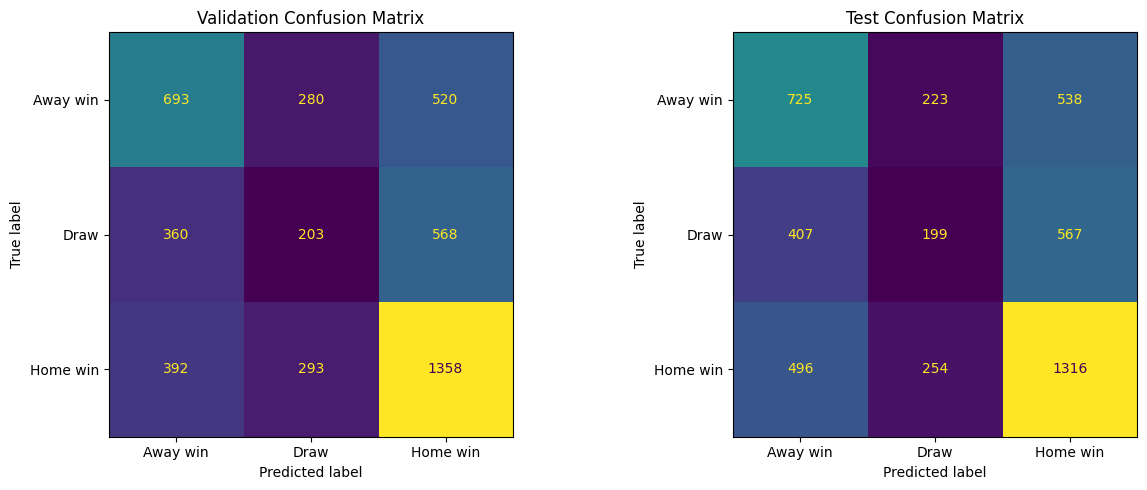


RUN COMPLETED
Experiment: Football_LightGBM_Tuning
Run name: LightGBM_TemporalSplit_Baseline
Run ID: 265eb0f932544d2fae931548fd6bdb51
Tracking URI: http://100.116.34.36:8080
Feature count: 92
Validation Macro F1: 0.4299
Validation Macro F2: 0.4327
Validation Draw Recall: 0.1795
🏃 View run LightGBM_TemporalSplit_Baseline at: http://100.116.34.36:8080/#/experiments/5/runs/265eb0f932544d2fae931548fd6bdb51
🧪 View experiment at: http://100.116.34.36:8080/#/experiments/5


In [ ]:

# ============================================================
# FOOTBALL 1X2 MULTICLASS - LIGHTGBM + MLFLOW
# Classes: 0 = Away Win, 1 = Draw, 2 = Home Win
#
# Input:
#   df: DataFrame da doc tu dbt / DuckDB
#
# Pipeline:
#   1. Validate input
#   2. Filter labeled + warm matches
#   3. Calendar-based train/valid/test split
#   4. Feature selection based ONLY on train
#   5. Train LightGBM with Draw sample weight
#   6. Evaluate validation and test
#   7. Save reports, predictions, confusion matrices,
#      feature importance, model and metadata to MLflow
# ============================================================

import os
import json
import tempfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.lightgbm

from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    log_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. CONFIGURATION
# ============================================================

DATE_COL = "match_date"
TARGET_COL = "y_result_code"
KEY_COL = "match_key"

LABELS = [0, 1, 2]
CLASS_NAMES = ["Away win", "Draw", "Home win"]
CLASS_MAPPING = {
    0: "Away win",
    1: "Draw",
    2: "Home win",
}

# Calendar cutoff - baseline proposal.
# Train:      through 2024-06-30
# Validation: 2024-07-01 through 2025-06-30
# Test:       from 2025-07-01 onward
TRAIN_END = pd.Timestamp("2024-06-30")
VALID_END = pd.Timestamp("2025-06-30")

MAX_MISSING_RATE = 0.15

# Keep fixed for the first comparable baseline.
DRAW_WEIGHT = 1.5

RANDOM_STATE = 42

EXPERIMENT_NAME = "Football_LightGBM_Tuning"
RUN_NAME = "LightGBM_TemporalSplit_Baseline"

TRACKING_URI = "http://100.116.34.36:8080"

MODEL_PARAMS = {
    "objective": "multiclass",
    "num_class": 3,
    "n_estimators": 500,
    "learning_rate": 0.03,
    "num_leaves": 15,
    "min_child_samples": 40,
    "reg_lambda": 1.0,
    "colsample_bytree": 0.85,
    "subsample": 0.85,
    "subsample_freq": 1,
    "random_state": RANDOM_STATE,
    "verbosity": -1,
    "n_jobs": -1,
}


# ============================================================
# 2. CHECK INPUT DATA
# ============================================================

if "df" not in globals():
    raise NameError(
        "Không tìm thấy DataFrame `df`. "
        "Hãy load dữ liệu từ dbt/DuckDB trước khi chạy."
    )

required_cols = [
    DATE_COL,
    TARGET_COL,
    "is_warm",
    "is_labeled",
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise KeyError(f"Thiếu cột bắt buộc: {missing_cols}")

data = df.copy()
n_raw = len(data)

# Normalize date to calendar day for splitting.
data[DATE_COL] = pd.to_datetime(
    data[DATE_COL], errors="coerce"
)

# Strictly validate target labels before filtering invalid rows.
target_numeric = pd.to_numeric(
    data[TARGET_COL], errors="coerce"
)

target_present = target_numeric.notna()
invalid_label = target_present & ~target_numeric.isin(LABELS)

if invalid_label.any():
    bad_values = sorted(
        target_numeric.loc[invalid_label].unique().tolist()
    )
    raise ValueError(
        f"{TARGET_COL} chứa nhãn ngoài {LABELS}: {bad_values}"
    )

# Convert boolean-like columns only if they are actual booleans.
# Avoid treating the string 'False' as True.
def as_true_mask(series):
    if pd.api.types.is_bool_dtype(series):
        return series.eq(True)

    normalized = series.astype("string").str.strip().str.lower()
    return normalized.isin(["true", "1", "yes", "y"])

warm_mask = as_true_mask(data["is_warm"])
labeled_mask = as_true_mask(data["is_labeled"])

keep_mask = (
    data[DATE_COL].notna()
    & warm_mask
    & labeled_mask
    & target_present
)

data = data.loc[keep_mask].copy()
data[TARGET_COL] = target_numeric.loc[data.index].astype("int8")

if data.empty:
    raise ValueError(
        "Không còn dữ liệu sau khi lọc ngày, is_warm, "
        "is_labeled và target."
    )

# The target must match the declared business mapping.
# This check validates codes, not their semantic meaning.
observed_labels = set(data[TARGET_COL].unique())
if not observed_labels.issubset(set(LABELS)):
    raise ValueError(f"Nhãn không hợp lệ: {observed_labels}")


# ============================================================
# 3. CHECK MATCH UNIQUENESS
# ============================================================

if KEY_COL in data.columns:
    if data[KEY_COL].isna().any():
        raise ValueError("Có match_key null trong dữ liệu được giữ.")

    duplicate_keys = data[KEY_COL].duplicated(keep=False)

    if duplicate_keys.any():
        examples = data.loc[
            duplicate_keys, [KEY_COL, DATE_COL, TARGET_COL]
        ].head(20)

        raise ValueError(
            "Một match_key có nhiều hơn một dòng. "
            "Cần xử lý duplicate trước khi train.\n"
            + examples.to_string(index=False)
        )


# ============================================================
# 4. REBUILD SPLIT BY CALENDAR DATE
# ============================================================

calendar_date = data[DATE_COL].dt.normalize()

data["split"] = np.select(
    [
        calendar_date <= TRAIN_END,
        calendar_date <= VALID_END,
    ],
    [
        "train",
        "valid",
    ],
    default="test",
)

split_order = ["train", "valid", "test"]

split_counts = (
    data["split"]
    .value_counts()
    .reindex(split_order, fill_value=0)
)

print("=" * 70)
print("DATA AUDIT")
print("=" * 70)
print("Rows before filtering:", n_raw)
print("Rows after filtering:", len(data))
print("\nRows per split:")
print(split_counts)

if (split_counts == 0).any():
    raise ValueError(
        "Có tập train/valid/test rỗng. "
        "Kiểm tra DATE_COL và các cutoff."
    )

# All matches on the same calendar date must belong to one split.
date_split_counts = (
    data.assign(_calendar_date=calendar_date)
    .groupby("_calendar_date")["split"]
    .nunique()
)

if (date_split_counts > 1).any():
    raise AssertionError(
        "Phát hiện ngày lịch bị chia sang nhiều split."
    )

# Verify the actual temporal boundaries.
train_df = data.loc[data["split"].eq("train")].copy()
valid_df = data.loc[data["split"].eq("valid")].copy()
test_df = data.loc[data["split"].eq("test")].copy()

assert train_df[DATE_COL].max().normalize() <= TRAIN_END
assert valid_df[DATE_COL].min().normalize() > TRAIN_END
assert valid_df[DATE_COL].max().normalize() <= VALID_END
assert test_df[DATE_COL].min().normalize() > VALID_END

print("\nDate range by split:")
for split_name, part in [
    ("train", train_df),
    ("valid", valid_df),
    ("test", test_df),
]:
    print(
        f"{split_name:>5}: "
        f"{part[DATE_COL].min()} -> {part[DATE_COL].max()}"
    )


# ============================================================
# 5. CHECK LABEL DISTRIBUTION
# ============================================================

print("\nLabel distribution:")
for split_name, part in [
    ("train", train_df),
    ("valid", valid_df),
    ("test", test_df),
]:
    print(f"\n{split_name.upper()} (n={len(part)}):")

    distribution = (
        part[TARGET_COL]
        .value_counts(normalize=True)
        .reindex(LABELS, fill_value=0)
    )

    distribution.index = [
        CLASS_MAPPING[i] for i in distribution.index
    ]

    print(distribution.round(4))

    absent = [
        label for label in LABELS
        if label not in set(part[TARGET_COL].unique())
    ]

    if absent:
        print(f"WARNING: {split_name} thiếu nhãn {absent}")

# Training must contain all three classes.
train_classes = np.sort(train_df[TARGET_COL].unique())

if not np.array_equal(train_classes, np.array(LABELS)):
    raise ValueError(
        "Train phải có đủ ba lớp [0, 1, 2]. "
        f"Hiện có {train_classes.tolist()}. "
        "Kiểm tra cutoff hoặc dữ liệu nhãn."
    )


# ============================================================
# 6. ENCODE FORM FEATURES
# ============================================================

def form_to_points(form):
    """
    W = 3 points, D = 1 point, L = 0 points.
    Return points / maximum possible points, in [0, 1].
    """
    if not isinstance(form, str) or not form.strip():
        return np.nan

    score_map = {"W": 3, "D": 1, "L": 0}
    values = [
        score_map[c]
        for c in form.upper()
        if c in score_map
    ]

    if not values:
        return np.nan

    return float(sum(values) / (3 * len(values)))


for col in ["f_home_form5", "f_away_form5"]:
    if col in data.columns:
        data[col + "_points_rate"] = data[col].map(
            form_to_points
        )

# Refresh split frames because new encoded columns were added.
train_df = data.loc[data["split"].eq("train")].copy()
valid_df = data.loc[data["split"].eq("valid")].copy()
test_df = data.loc[data["split"].eq("test")].copy()


# ============================================================
# 7. FEATURE SELECTION - TRAIN ONLY
# ============================================================

# Use numeric f_ columns only.
# Target columns (y_), identifiers, split, dates, and raw form strings
# are not eligible as predictors.
features_all = [
    col
    for col in data.columns
    if col.startswith("f_")
    and pd.api.types.is_numeric_dtype(data[col])
]

features_all = list(dict.fromkeys(features_all))

if not features_all:
    raise ValueError(
        "Không tìm thấy feature f_ dạng số."
    )

X_train_candidates = train_df[features_all].copy()

# Replace +/- inf with NaN, then let LightGBM handle missing values.
# This is deterministic and does not estimate anything from validation/test.
for part in [X_train_candidates]:
    part.replace([np.inf, -np.inf], np.nan, inplace=True)

missing_rate_train = X_train_candidates.isna().mean()
nunique_train = X_train_candidates.nunique(dropna=True)

features = [
    col
    for col in features_all
    if missing_rate_train[col] <= MAX_MISSING_RATE
    and nunique_train[col] > 1
]

if not features:
    raise ValueError(
        "Không còn feature sau lọc missing/variance. "
        "Hãy kiểm tra data hoặc MAX_MISSING_RATE."
    )

# Report missingness by split for selected features.
missing_report = pd.DataFrame({
    "train": train_df[features].isna().mean(),
    "valid": valid_df[features].isna().mean(),
    "test": test_df[features].isna().mean(),
})

missing_report["max_split_gap"] = (
    missing_report[["train", "valid", "test"]].max(axis=1)
    - missing_report[["train", "valid", "test"]].min(axis=1)
)

print("\nFeature selection:")
print("Numeric feature candidates:", len(features_all))
print("Selected features:", len(features))
print("Train missing threshold:", MAX_MISSING_RATE)

print("\nTop 15 selected features with largest missing-rate gap:")
print(
    missing_report.sort_values(
        "max_split_gap", ascending=False
    ).head(15).round(3)
)

# Build final matrices with the same feature order.
X_train = train_df[features].copy()
X_valid = valid_df[features].copy()
X_test = test_df[features].copy()

for X in [X_train, X_valid, X_test]:
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    for col in features:
        X[col] = pd.to_numeric(X[col], errors="coerce").astype("float32")

y_train = train_df[TARGET_COL].astype("int8").copy()
y_valid = valid_df[TARGET_COL].astype("int8").copy()
y_test = test_df[TARGET_COL].astype("int8").copy()

feature_names = list(X_train.columns)

if list(X_valid.columns) != feature_names:
    raise ValueError("Feature validation không khớp train.")

if list(X_test.columns) != feature_names:
    raise ValueError("Feature test không khớp train.")

if len(set(feature_names)) != len(feature_names):
    raise ValueError("Tên feature bị trùng.")

# Confirm feature matrices contain no infinite values.
for split_name, X in [
    ("train", X_train),
    ("valid", X_valid),
    ("test", X_test),
]:
    if np.isinf(X.to_numpy(dtype=np.float64)).any():
        raise ValueError(f"{split_name} vẫn có inf/-inf.")

print("\nFinal matrix shapes:")
print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("X_test :", X_test.shape)


# ============================================================
# 8. DEFINE EVALUATION FUNCTION
# ============================================================

def evaluate_multiclass(y_true, y_pred, y_proba):
    result = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "macro_precision": precision_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0,
        ),
        "macro_recall": recall_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0,
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0,
        ),
        "macro_f2": fbeta_score(
            y_true,
            y_pred,
            labels=LABELS,
            beta=2,
            average="macro",
            zero_division=0,
        ),
        "weighted_precision": precision_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="weighted",
            zero_division=0,
        ),
        "weighted_recall": recall_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="weighted",
            zero_division=0,
        ),
        "weighted_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="weighted",
            zero_division=0,
        ),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "log_loss": log_loss(
            y_true, y_proba, labels=LABELS
        ),
    }

    report = classification_report(
        y_true,
        y_pred,
        labels=LABELS,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )

    for class_name in CLASS_NAMES:
        key = class_name.lower().replace(" ", "_")
        class_metrics = report[class_name]

        result[f"{key}_precision"] = class_metrics["precision"]
        result[f"{key}_recall"] = class_metrics["recall"]
        result[f"{key}_f1"] = class_metrics["f1-score"]

        class_code = CLASS_NAMES.index(class_name)
        y_true_binary = (np.asarray(y_true) == class_code).astype(int)
        y_pred_binary = (np.asarray(y_pred) == class_code).astype(int)

        result[f"{key}_f2"] = fbeta_score(
            y_true_binary,
            y_pred_binary,
            beta=2,
            zero_division=0,
        )

    return result


# ============================================================
# 9. TRAIN LIGHTGBM + LOG TO MLFLOW
# ============================================================

# Draw receives a higher training loss weight.
# Draw receives a higher training loss weight.
sample_weight = np.where(
    y_train.to_numpy() == 1,
    DRAW_WEIGHT,
    1.0
).astype(np.float64)

assert len(sample_weight) == len(y_train)
assert np.isfinite(sample_weight).all()

print("Sample weights:")
print(f"  Normal classes: 1.0")
print(f"  Draw weight:    {DRAW_WEIGHT}")
print(f"  Draw samples:   {(y_train.to_numpy() == 1).sum():,}")
print(f"  Total samples:  {len(sample_weight):,}")

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

model = LGBMClassifier(**MODEL_PARAMS)

with mlflow.start_run(run_name=RUN_NAME) as run:
    run_id = run.info.run_id

    # ---------------------------
    # Log configuration
    # ---------------------------
    mlflow.log_params(MODEL_PARAMS)
    mlflow.log_param("draw_weight", DRAW_WEIGHT)
    mlflow.log_param("n_features", len(feature_names))
    mlflow.log_param("n_train", len(X_train))
    mlflow.log_param("n_validation", len(X_valid))
    mlflow.log_param("n_test", len(X_test))
    mlflow.log_param("class_mapping", "0=Away,1=Draw,2=Home")
    mlflow.log_param("split_method", "calendar_date_cutoff")
    mlflow.log_param("train_end", str(TRAIN_END.date()))
    mlflow.log_param("valid_end", str(VALID_END.date()))
    mlflow.log_param("max_missing_rate_train", MAX_MISSING_RATE)
    mlflow.log_param("date_column", DATE_COL)
    mlflow.log_param("target_column", TARGET_COL)

    for split_name, part in [
        ("train", train_df),
        ("valid", valid_df),
        ("test", test_df),
    ]:
        mlflow.log_param(
            f"{split_name}_start_date",
            str(part[DATE_COL].min().date()),
        )
        mlflow.log_param(
            f"{split_name}_end_date",
            str(part[DATE_COL].max().date()),
        )

    print("\nTraining LightGBM...")
    print("MLflow run ID:", run_id)

    model.fit(
        X_train,
        y_train,
        sample_weight=sample_weight,
    )

    # ---------------------------
    # Predictions
    # ---------------------------
    valid_proba = model.predict_proba(X_valid)
    test_proba = model.predict_proba(X_test)

    model_classes = list(model.classes_)
    if model_classes != LABELS:
        raise ValueError(
            f"Model classes {model_classes} != expected {LABELS}"
        )

    valid_pred = np.argmax(valid_proba, axis=1)
    test_pred = np.argmax(test_proba, axis=1)

    # ---------------------------
    # Metrics
    # ---------------------------
    valid_metrics = evaluate_multiclass(
        y_valid.to_numpy(), valid_pred, valid_proba
    )
    test_metrics = evaluate_multiclass(
        y_test.to_numpy(), test_pred, test_proba
    )

    print("\n" + "=" * 70)
    print("VALIDATION METRICS")
    print("=" * 70)
    print(pd.Series(valid_metrics).round(4).to_string())

    print("\nVALIDATION CLASSIFICATION REPORT")
    print(classification_report(
        y_valid,
        valid_pred,
        labels=LABELS,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    ))

    print("\n" + "=" * 70)
    print("TEST METRICS - DIAGNOSTIC UNTIL MODEL IS FROZEN")
    print("=" * 70)
    print(pd.Series(test_metrics).round(4).to_string())

    print("\nTEST CLASSIFICATION REPORT")
    print(classification_report(
        y_test,
        test_pred,
        labels=LABELS,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    ))

    # ---------------------------
    # Confusion matrices
    # ---------------------------
    cm_valid = confusion_matrix(
        y_valid, valid_pred, labels=LABELS
    )
    cm_test = confusion_matrix(
        y_test, test_pred, labels=LABELS
    )

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_valid,
        display_labels=CLASS_NAMES,
    ).plot(
        ax=axes[0],
        values_format="d",
        colorbar=False,
    )
    axes[0].set_title("Validation Confusion Matrix")

    ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=CLASS_NAMES,
    ).plot(
        ax=axes[1],
        values_format="d",
        colorbar=False,
    )
    axes[1].set_title("Test Confusion Matrix")

    plt.tight_layout()

    # ---------------------------
    # Feature importance
    # ---------------------------
    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": model.feature_importances_,
    }).sort_values("importance", ascending=False)

    print("\nTop 20 feature importance:")
    print(importance_df.head(20).to_string(index=False))

    # ---------------------------
    # Save artifacts
    # ---------------------------
    with tempfile.TemporaryDirectory() as tmpdir:

        # Metrics
        metrics_df = pd.DataFrame({
            "validation": pd.Series(valid_metrics),
            "test": pd.Series(test_metrics),
        })
        metrics_path = os.path.join(
            tmpdir, "multiclass_metrics.csv"
        )
        metrics_df.to_csv(metrics_path, index=True)
        mlflow.log_artifact(metrics_path)

        # Classification reports
        for split_name, y_true, y_pred in [
            ("validation", y_valid, valid_pred),
            ("test", y_test, test_pred),
        ]:
            report = classification_report(
                y_true,
                y_pred,
                labels=LABELS,
                target_names=CLASS_NAMES,
                output_dict=True,
                zero_division=0,
            )

            report_path = os.path.join(
                tmpdir,
                f"classification_report_{split_name}.json",
            )
            with open(report_path, "w", encoding="utf-8") as f:
                json.dump(report, f, ensure_ascii=False, indent=2)

            mlflow.log_artifact(report_path)

        # Confusion matrices
        for split_name, cm in [
            ("validation", cm_valid),
            ("test", cm_test),
        ]:
            cm_df = pd.DataFrame(
                cm,
                index=[f"true_{c}" for c in CLASS_NAMES],
                columns=[f"pred_{c}" for c in CLASS_NAMES],
            )

            cm_path = os.path.join(
                tmpdir, f"confusion_matrix_{split_name}.csv"
            )
            cm_df.to_csv(cm_path)
            mlflow.log_artifact(cm_path)

        # Predictions and probabilities
        for split_name, part, y_true, y_pred, y_proba in [
            (
                "validation",
                valid_df,
                y_valid.to_numpy(),
                valid_pred,
                valid_proba,
            ),
            (
                "test",
                test_df,
                y_test.to_numpy(),
                test_pred,
                test_proba,
            ),
        ]:
            prediction_columns = {}

            if KEY_COL in part.columns:
                prediction_columns[KEY_COL] = part[KEY_COL].to_numpy()

            prediction_columns[DATE_COL] = part[DATE_COL].to_numpy()
            prediction_columns["y_true"] = y_true
            prediction_columns["y_pred"] = y_pred
            prediction_columns["p_away"] = y_proba[:, 0]
            prediction_columns["p_draw"] = y_proba[:, 1]
            prediction_columns["p_home"] = y_proba[:, 2]

            pred_df = pd.DataFrame(prediction_columns)

            pred_path = os.path.join(
                tmpdir, f"predictions_{split_name}.csv"
            )
            pred_df.to_csv(pred_path, index=False)
            mlflow.log_artifact(pred_path)

        # Feature importance and feature names
        importance_path = os.path.join(
            tmpdir, "feature_importance.csv"
        )
        importance_df.to_csv(importance_path, index=False)
        mlflow.log_artifact(importance_path)

        features_path = os.path.join(
            tmpdir, "feature_names.json"
        )
        with open(features_path, "w", encoding="utf-8") as f:
            json.dump(feature_names, f, ensure_ascii=False, indent=2)
        mlflow.log_artifact(features_path)

        # Data and training metadata
        metadata = {
            "run_id": run_id,
            "date_column": DATE_COL,
            "target_column": TARGET_COL,
            "class_mapping": CLASS_MAPPING,
            "train_end": str(TRAIN_END.date()),
            "valid_end": str(VALID_END.date()),
            "max_missing_rate_train": MAX_MISSING_RATE,
            "draw_weight": DRAW_WEIGHT,
            "n_raw": int(n_raw),
            "n_after_filter": int(len(data)),
            "n_train": int(len(X_train)),
            "n_validation": int(len(X_valid)),
            "n_test": int(len(X_test)),
            "n_features": int(len(feature_names)),
            "train_missing_rate_threshold": MAX_MISSING_RATE,
        }

        metadata_path = os.path.join(
            tmpdir, "training_metadata.json"
        )
        with open(metadata_path, "w", encoding="utf-8") as f:
            json.dump(metadata, f, ensure_ascii=False, indent=2)
        mlflow.log_artifact(metadata_path)

        # Confusion matrix figure
        fig_path = os.path.join(
            tmpdir, "confusion_matrices.png"
        )
        fig.savefig(fig_path, dpi=160, bbox_inches="tight")
        mlflow.log_artifact(fig_path)

        # Log metrics
        all_mlflow_metrics = {
            **{
                f"valid_{k}": float(v)
                for k, v in valid_metrics.items()
            },
            **{
                f"test_{k}": float(v)
                for k, v in test_metrics.items()
            },
        }
        mlflow.log_metrics(all_mlflow_metrics)

        # Log LightGBM model
        mlflow.lightgbm.log_model(
            model,
            artifact_path="model",
        )

    plt.show()
    plt.close(fig)

    print("\n" + "=" * 70)
    print("RUN COMPLETED")
    print("Experiment:", EXPERIMENT_NAME)
    print("Run name:", RUN_NAME)
    print("Run ID:", run_id)
    print("Tracking URI:", TRACKING_URI)
    print("Feature count:", len(feature_names))
    print(f"Validation Macro F1: {valid_metrics['macro_f1']:.4f}")
    print(f"Validation Macro F2: {valid_metrics['macro_f2']:.4f}")
    print(f"Validation Draw Recall: {valid_metrics['draw_recall']:.4f}")
    print("=" * 70)


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

proba = model.predict_proba(X_valid)
y_true = np.asarray(y_valid)

# Baseline: cách dự đoán thông thường
pred_baseline = np.argmax(proba, axis=1)

rows = []

for threshold in np.arange(0.20, 0.451, 0.01):
    # Mặc định chỉ chọn giữa Away và Home
    pred = np.where(proba[:, 0] >= proba[:, 2], 0, 2)

    # Chỉ chọn Draw khi xác suất Draw đạt ngưỡng
    pred[proba[:, 1] >= threshold] = 1

    rows.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(y_true, pred),
        "balanced_acc": balanced_accuracy_score(y_true, pred),
        "macro_f1": f1_score(
            y_true, pred, labels=[0, 1, 2],
            average="macro", zero_division=0
        ),
        "draw_precision": precision_score(
            y_true, pred, labels=[0, 1, 2],
            average=None, zero_division=0
        )[1],
        "draw_recall": recall_score(
            y_true, pred, labels=[0, 1, 2],
            average=None, zero_division=0
        )[1],
        "draw_f1": f1_score(
            y_true, pred, labels=[0, 1, 2],
            average=None, zero_division=0
        )[1],
        "pred_draw_rate": np.mean(pred == 1),
    })

results = pd.DataFrame(rows)

print("BASELINE — argmax")
print({
    "accuracy": round(accuracy_score(y_true, pred_baseline), 4),
    "macro_f1": round(
        f1_score(y_true, pred_baseline, average="macro"), 4
    ),
})

print("\nTOP 10 THRESHOLDS BY MACRO-F1")
print(
    results.sort_values("macro_f1", ascending=False)
    .head(10)
    .round(4)
    .to_string(index=False)
)

print("\nTOP 10 THRESHOLDS BY DRAW-F1")
print(
    results.sort_values("draw_f1", ascending=False)
    .head(10)
    .round(4)
    .to_string(index=False)
)


BASELINE — argmax
{'accuracy': 0.483, 'macro_f1': 0.4299}

TOP 10 THRESHOLDS BY MACRO-F1
 threshold  accuracy  balanced_acc  macro_f1  draw_precision  draw_recall  draw_f1  pred_draw_rate
      0.36    0.4613        0.4278    0.4281          0.2554       0.2493   0.2523          0.2366
      0.35    0.4538        0.4257    0.4273          0.2549       0.2847   0.2690          0.2706
      0.34    0.4453        0.4236    0.4253          0.2562       0.3263   0.2870          0.3085
      0.37    0.4660        0.4269    0.4246          0.2476       0.2069   0.2254          0.2025
      0.38    0.4705        0.4259    0.4198          0.2403       0.1698   0.1990          0.1712
      0.33    0.4345        0.4182    0.4195          0.2508       0.3554   0.2941          0.3435
      0.39    0.4768        0.4282    0.4185          0.2423       0.1468   0.1828          0.1468
      0.32    0.4262        0.4161    0.4158          0.2518       0.3926   0.3068          0.3778
      0.40    0.4830

In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
)

proba = model.predict_proba(X_valid)
y_true = np.asarray(y_valid)

rows = []

for class_id, class_name in [
    (0, "Away win"),
    (1, "Draw"),
    (2, "Home win"),
]:
    y_binary = (y_true == class_id).astype(int)
    p = proba[:, class_id]

    rows.append({
        "class": class_name,
        "actual_rate": y_binary.mean(),
        "mean_probability": p.mean(),
        "roc_auc_ovr": roc_auc_score(y_binary, p),
        "average_precision": average_precision_score(y_binary, p),
    })

print("ONE-VS-REST PROBABILITY DISCRIMINATION")
print(pd.DataFrame(rows).round(4).to_string(index=False))

print("\nMULTICLASS LOG LOSS")
print(round(log_loss(y_true, proba, labels=[0, 1, 2]), 4))

print("\nDRAW PROBABILITY BY ACTUAL CLASS")
df = pd.DataFrame({
    "actual": y_true,
    "p_draw": proba[:, 1],
})

print(
    df.groupby("actual")["p_draw"]
    .agg(["count", "mean", "median", "std"])
    .rename(index={
        0: "Away win",
        1: "Draw",
        2: "Home win",
    })
    .round(4)
)


ONE-VS-REST PROBABILITY DISCRIMINATION
   class  actual_rate  mean_probability  roc_auc_ovr  average_precision
Away win       0.3199            0.3082       0.6723             0.4821
    Draw       0.2423            0.2908       0.5254             0.2531
Home win       0.4378            0.4009       0.6703             0.5975

MULTICLASS LOG LOSS
1.0339

DRAW PROBABILITY BY ACTUAL CLASS
          count    mean  median     std
actual                                 
Away win   1493  0.2933  0.2920  0.0957
Draw       1131  0.2979  0.2953  0.0889
Home win   2043  0.2851  0.2857  0.0935


In [ ]:

import numpy as np
import pandas as pd

from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

y_valid_np = np.asarray(y_valid)

def draw_auc_scorer(estimator, X, y):
    y_draw = (np.asarray(y) == 1).astype(int)
    p_draw = estimator.predict_proba(X)[:, 1]
    return roc_auc_score(y_draw, p_draw)

# Baseline AUC riêng của Draw
baseline_draw_auc = draw_auc_scorer(
    model, X_valid, y_valid_np
)

print("Baseline Draw ROC-AUC:", round(baseline_draw_auc, 4))

# Đo mức giảm AUC khi xáo trộn từng feature
perm = permutation_importance(
    model,
    X_valid,
    y_valid_np,
    scoring=draw_auc_scorer,
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

draw_importance = pd.DataFrame({
    "feature": X_valid.columns,
    "auc_drop_mean": perm.importances_mean,
    "auc_drop_std": perm.importances_std,
})

print("\nFEATURES THAT HELP DRAW DISCRIMINATION")
print(
    draw_importance.sort_values(
        "auc_drop_mean", ascending=False
    ).head(25).round(5).to_string(index=False)
)

print("\nFEATURES WITH NEGATIVE IMPORTANCE")
print(
    draw_importance.sort_values(
        "auc_drop_mean", ascending=True
    ).head(15).round(5).to_string(index=False)
)


Baseline Draw ROC-AUC: 0.5254

FEATURES THAT HELP DRAW DISCRIMINATION
              feature  auc_drop_mean  auc_drop_std
       f_diff_s_ga_pg        0.00664       0.00322
       f_home_s_gf_pg        0.00410       0.00128
       f_diff_s_gd_pg        0.00397       0.00200
        f_home_gf_l10        0.00328       0.00102
     f_diff_rest_days        0.00259       0.00165
    f_away_side_ga_l5        0.00223       0.00119
         f_away_s_ppg        0.00195       0.00075
         f_diff_n_30d        0.00188       0.00073
   f_home_side_pts_l5        0.00186       0.00089
    f_home_cs_rate_l5        0.00138       0.00036
       f_away_s_gd_pg        0.00132       0.00132
       f_away_s_gf_pg        0.00129       0.00271
    f_home_side_ga_l5        0.00127       0.00097
   f_diff_side_pts_l5        0.00099       0.00056
f_home_over25_rate_l5        0.00095       0.00059
         f_home_n_30d        0.00094       0.00043
         f_home_ga_l3        0.00092       0.00028
        f_ho

Nhận định: tín hiệu Draw mà model đang sử dụng vẫn chủ yếu đến từ thống kê bàn thắng, bàn thua, sức mạnh đội và lịch thi đấu. Không có feature đơn lẻ nào tạo ra bước nhảy lớn về khả năng phân biệt Draw.